# Systemy AI – Laboratorium 2
## Od liczb do decyzji: jak klasyfikator zamienia dane na odpowiedź 0/1

**Cel:** zrozumieć, co dzieje się „w środku” prostego klasyfikatora (standaryzacja → wynik liniowy → prawdopodobieństwo → decyzja), a potem zapoznać się z pierwszym prawdziwym zbiorem danych (Titanic).

**Zasady** (jak poprzednio)
- Rozwiązania wpisuj w komórkach `# Twoje rozwiązanie`, odpowiedzi opisowe w komórkach *Twoja odpowiedź*.
- Komórek `# TEST` nie zmieniaj. Nazwy zmiennych podane w treści zadań są obowiązkowe, bo testy z nich korzystają.
- Przed oddaniem: *Środowisko wykonawcze → Uruchom ponownie i uruchom wszystko*.


---
## Część A. NumPy: od liczb do decyzji

### Po co ta część?
Prawie każdy klasyfikator, od regresji logistycznej po ostatnią warstwę dużej sieci neuronowej, podejmuje decyzję według tego samego schematu:

```
 dane X  ──►  standaryzacja  ──►  wynik z = X·w + b  ──►  prawdopodobieństwo p̂ = σ(z)  ──►  decyzja ŷ = [p̂ ≥ próg]
 (liczby)     (wspólna skala)     (dowolna liczba)        (liczba z przedziału 0–1)         (0 albo 1)
```

Dziś przejdziemy ten schemat krok po kroku, licząc wszystko samodzielnie w NumPy. Wagi $w$ i $b$ są **podane z góry**. Skąd się biorą (czyli na czym polega **uczenie** modelu), zobaczymy na kolejnych zajęciach.

### Oznaczenia i kształty tablic

| Symbol | Co to jest | Kształt w NumPy | W naszym przykładzie |
|---|---|---|---|
| $X$ | dane: **wiersz = jeden przykład** (np. pacjent), **kolumna = jedna cecha** (np. wiek) | `(n, d)` | `(5, 2)`: 5 przykładów, 2 cechy |
| $w$ | wagi: po jednej liczbie na każdą cechę | `(d,)` | `(2,)` |
| $b$ | wyraz wolny (*bias*): jedna liczba | skalar | `-0.2` |
| $z$ | wynik liniowy: jedna liczba na przykład | `(n,)` | `(5,)` |
| $\hat{p}$, $\hat{y}$ | prawdopodobieństwo i decyzja dla każdego przykładu | `(n,)` | `(5,)` |

Jeśli w trakcie pracy coś „nie pasuje”, pierwszy krok to zawsze `print(tablica.shape)`.

In [1]:
import numpy as np

X = np.array([[ 0.5,  1.2],
              [ 1.5, -0.3],
              [-1.0,  0.8],
              [ 2.0,  2.0],
              [ 0.0,  0.0]])        # 5 przykładów, 2 cechy
w = np.array([1.0, -0.5])           # wagi cech
b = -0.2                            # wyraz wolny (bias)
y_c = np.array([0, 1, 0, 1, 0])     # prawdziwe etykiety

print("X:", X.shape, " w:", w.shape, " y_c:", y_c.shape)

X: (5, 2)  w: (2,)  y_c: (5,)


### Zadanie A0. Funkcja z Lab 1
Wklej poniżej swoją funkcję `binary_metrics(y_true, y_pred)` z Lab 1 (zadanie C2). Przypomnienie: zwraca słownik z kluczami `"TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"`, a metryka z zerowym mianownikiem ma wartość `0.0`. Będzie potrzebna w obu częściach.

In [2]:
# Wklej tutaj swoją funkcję binary_metrics z Lab 1

def binary_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    TN = np.sum((y_true == 0) & (y_pred == 0))

    accuracy = (TP + TN) / (TP + TN + FP + FN) if (TP + TN + FP + FN) != 0 else 0.0
    precision = TP / (TP + FP) if (TP + FP) != 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) != 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) != 0 else 0.0

    metryki = {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

    return metryki

In [3]:
# TEST
_m = binary_metrics([1, 0, 1, 1, 0, 0, 1, 0, 1, 0], [1, 0, 1, 0, 0, 1, 1, 0, 0, 0])
assert (_m["TP"], _m["FP"], _m["FN"], _m["TN"]) == (3, 1, 2, 4)
assert abs(_m["accuracy"] - 0.7) < 1e-9 and abs(_m["f1"] - 2 / 3) < 1e-9
assert binary_metrics([1, 0, 0, 0], [0, 0, 0, 0])["precision"] == 0.0
print("A0 OK")

A0 OK


### Krok 1. Standaryzacja: wspólna skala dla cech

**Problem.** Cechy bywają w zupełnie różnych jednostkach. Na Titanicu wiek to liczby 0–80, a cena biletu 0–500. Gdyby wrzucić je do modelu bez zmian, cecha o dużych liczbach „przekrzyczałaby” pozostałe, a wartości wag nie dałoby się ze sobą porównać.

**Rozwiązanie.** Dla **każdej kolumny osobno** odejmujemy jej średnią i dzielimy przez jej odchylenie standardowe:

$$x' = \frac{x - \mu_{\text{kolumny}}}{\sigma_{\text{kolumny}}}$$

Po tej operacji każda kolumna ma średnią 0 i odchylenie 1. Wartość $x' = 1.5$ czytamy: „półtora odchylenia powyżej średniej”, niezależnie od tego, czy chodzi o lata, czy o złotówki.

**Dwa narzędzia NumPy, których potrzebujesz:**

1. **Parametr `axis`.** `X.mean(axis=0)` liczy średnią *wzdłuż wierszy*, czyli osobno dla każdej kolumny; wynik ma kształt `(2,)`. Dla porównania `X.mean()` daje jedną liczbę ze wszystkich elementów, a `X.mean(axis=1)` średnią każdego wiersza.

   ```
   X =  [[ 0.5,  1.2],      X.mean(axis=0) = [0.6, 0.74]   ← jedna liczba na kolumnę
         [ 1.5, -0.3],
         ...         ]
   ```

2. **Broadcasting.** Odejmując tablicę `(2,)` od macierzy `(5, 2)`, NumPy sam „powiela” wektor na każdy z 5 wierszy. Dzięki temu `X - X.mean(axis=0)` działa bez żadnej pętli.

### Zadanie A1. Funkcja `zscore`
Napisz funkcję `zscore(X)`, która standaryzuje każdą kolumnę macierzy (bez pętli, przez `axis=0` i broadcasting). Wynik dla `X` zapisz w `X_std` i sprawdź, że średnie kolumn wynoszą 0, a odchylenia 1.

In [4]:
# Twoje rozwiązanie

def zscore(X):
  X = np.asarray(X)
  X_mean = X.mean(axis=0)
  X_std = X.std(axis=0)
  return (X - X_mean) / X_std

X_std = zscore(X)

print(X_std.mean(axis=0))
print(X_std.std(axis=0))

[-2.22044605e-17 -2.22044605e-17]
[1. 1.]


In [5]:
# TEST
assert X_std.shape == X.shape
assert np.allclose(X_std.mean(axis=0), 0) and np.allclose(X_std.std(axis=0), 1)
assert np.allclose(zscore([[1, 10], [3, 30]]), [[-1, -1], [1, 1]])
print("A1 OK")

A1 OK


> **Uwaga na dalszą część.** W zadaniach A2–A4 używamy **oryginalnego** `X`, bo wagi `w` zostały dobrane właśnie do niego. W prawdziwym modelu standaryzujemy dane *przed* uczeniem, a potem tymi samymi $\mu$ i $\sigma$ przekształcamy każdy nowy przykład.

### Krok 2. Wynik liniowy $z = Xw + b$

Dla jednego przykładu $x = (x_1, x_2)$ wynik to ważona suma cech plus wyraz wolny:

$$z = w_1 x_1 + w_2 x_2 + b$$

Policzmy go ręcznie dla **pierwszego wiersza** $x = (0.5,\ 1.2)$:

$$z = 1.0 \cdot 0.5 + (-0.5) \cdot 1.2 + (-0.2) = 0.5 - 0.6 - 0.2 = -0.3$$

**Jak to czytać:**
- waga **dodatnia** ($w_1 = 1.0$): im większa cecha 1, tym większe $z$, czyli tym bardziej model „skłania się” ku klasie 1;
- waga **ujemna** ($w_2 = -0.5$): im większa cecha 2, tym bardziej model skłania się ku klasie 0;
- $z$ może być dowolną liczbą, ujemną lub dodatnią. **To jeszcze nie jest prawdopodobieństwo.**

Iloczyn macierzy i wektora `X @ w` liczy taką ważoną sumę **dla wszystkich wierszy naraz**: wynik ma kształt `(5,)`.

### Zadanie A2. Trzy sposoby na to samo
1. Policz $z$ dla pierwszego wiersza „po kolei” (indeksowanie `X[0, 0]`, `X[0, 1]`) i zapisz w `z0`.
2. Policz $z$ dla wszystkich wierszy **pętlą** `for` i zapisz jako tablicę `z_loop`.
3. Policz to samo jedną linią z operatorem `@` i zapisz w `z`.
4. Sprawdź `np.allclose(z_loop, z)` i wypisz kształt `z`.

In [6]:
# Twoje rozwiązanie,

z0 = X[0, 0] * w[0] + X[0, 1] * w[1] + b

print(z0)

z_loop = []
for i in range(len(X)):
  z_loop.append(X[i, 0] * w[0] + X[i, 1] * w[1] + b)

print(z_loop)

z = X @ w + b

print(z)

-0.3
[np.float64(-0.3), np.float64(1.45), np.float64(-1.5999999999999999), np.float64(0.8), np.float64(-0.2)]
[-0.3   1.45 -1.6   0.8  -0.2 ]


In [7]:
# TEST
assert abs(z0 - (-0.3)) < 1e-9
assert np.allclose(z_loop, [-0.3, 1.45, -1.6, 0.8, -0.2]) and np.allclose(z, z_loop)
assert z.shape == (5,)
print("A2 OK")

A2 OK


### Krok 3. Sigmoida: z dowolnej liczby robimy prawdopodobieństwo

Funkcja sigmoidalna (logistyczna)

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

„ściska” całą oś liczbową do przedziału $(0, 1)$:

| $z$ | −4 | −2 | 0 | 2 | 4 |
|---|---|---|---|---|---|
| $\sigma(z)$ | 0.018 | 0.119 | **0.5** | 0.881 | 0.982 |

- $z = 0$ oznacza „nie wiem”: $\sigma(0) = 0.5$;
- duże dodatnie $z$ → prawdopodobieństwo bliskie 1, duże ujemne → bliskie 0;
- funkcja jest rosnąca, więc **kolejność przykładów się nie zmienia**: kto miał większe $z$, ma większe $\hat{p}$.

W NumPy używaj `np.exp`, a nie `math.exp`: tylko `np.exp` działa na całej tablicy naraz.

### Zadanie A3. Sigmoida i jej wykres
1. Napisz funkcję `sigmoid(z)` działającą zarówno na liczbach, jak i na tablicach NumPy.
2. Napisz funkcję `predict_proba(X, w, b)`, która zwraca $\hat{p} = \sigma(Xw + b)$. Policz `proba = predict_proba(X, w, b)`.
3. Narysuj wykres $\sigma(z)$ dla `z_grid = np.linspace(-6, 6, 200)`. Na ten sam wykres nanieś nasze 5 przykładów jako punkty $(z_i, \hat{p}_i)$: **pokoloruj je według prawdziwej klasy** `y_c` (np. dwa wywołania `ax.scatter` z maską `y_c == 0` i `y_c == 1`). Dodaj poziomą linię na wysokości 0.5 (`ax.axhline`), podpisz osie i dodaj legendę.

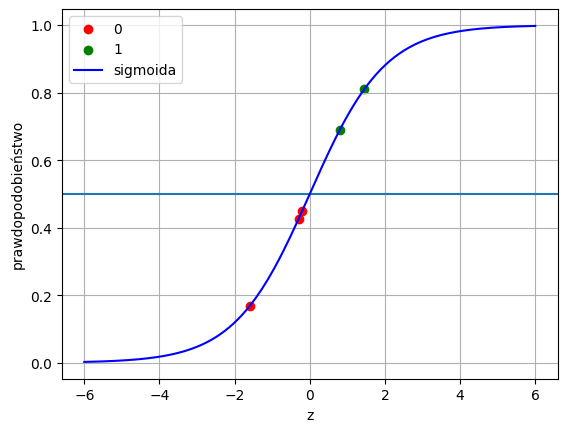

In [8]:
import matplotlib.pyplot as plt

# Twoje rozwiązanie

def sigmoid(z):
  return 1 / (1 + np.exp(-z))

def predict_proba(X, w, b):
  return sigmoid(X @ w + b)

proba = predict_proba(X, w, b)

z_grid = np.linspace(-6, 6, 200)
z_loop = np.asarray(z_loop)

plt.scatter(z_loop[y_c == 0], proba[y_c == 0], color="red", label="0")
plt.scatter(z_loop[y_c == 1], proba[y_c == 1], color="green", label="1")
plt.axhline(0.5)

plt.plot(z_grid, sigmoid(z_grid), color="blue", label="sigmoida")
plt.xlabel("z")
plt.ylabel("prawdopodobieństwo")
plt.legend()
plt.grid(True)

In [9]:
# TEST
assert sigmoid(0) == 0.5 and np.allclose(sigmoid(np.array([-100.0, 100.0])), [0, 1])
assert np.allclose(proba, [0.42556, 0.80999, 0.16798, 0.68997, 0.45017], atol=1e-4)
print("A3 OK")

A3 OK


### Krok 4. Próg decyzyjny: z prawdopodobieństwa robimy decyzję

Ostatni krok to porównanie $\hat{p}$ z progiem: $\hat{y} = 1$, gdy $\hat{p} \ge \text{próg}$, w przeciwnym razie $\hat{y} = 0$.

**Ważne:** próg **nie jest uczony**. Wybiera go człowiek, w zależności od tego, który błąd jest w danym zastosowaniu droższy:
- **niski próg** → model częściej mówi „1”: mniej przeoczeń (FN), więcej fałszywych alarmów (FP), czyli wyższy recall i niższa precision;
- **wysoki próg** → model mówi „1” tylko, gdy jest pewny: mniej FP, więcej FN.

Przypomnij sobie pytanie o wykrywanie choroby z mini-eksperymentu w Lab 1: to jest właśnie to miejsce, w którym tę decyzję się podejmuje.

### Zadanie A4. Decyzja i jej ocena
1. Napisz funkcję `predict(X, w, b, threshold=0.5)`, która zwraca etykiety 0/1 jako tablicę liczb całkowitych (`.astype(int)`).
2. Policz `y_hat = predict(X, w, b)` oraz `binary_metrics(y_c, y_hat)`.
3. Powtórz dla progu 0.7 (`y_hat_07`) i progu 0.4 (`y_hat_04`).
4. Zbierz wyniki w małej tabeli (wiersz = próg; kolumny `precision`, `recall`) i odpowiedz na pytania pod spodem.

In [10]:
import pandas as pd

# Twoje rozwiązanie
def predict(X, w, b, threshold=0.5):
  return (predict_proba(X, w, b) >= threshold).astype(int)

y_hat = predict(X, w, b)
y_hat_metrics = binary_metrics(y_c, y_hat)
print(y_hat)
print(y_hat_metrics)

y_hat_07 = predict(X, w, b, threshold=0.7)
y_hat_07_metrics = binary_metrics(y_c, y_hat_07)
print(y_hat_07)
print(y_hat_07_metrics)

y_hat_04 = predict(X, w, b, threshold=0.4)
y_hat_04_metrics = binary_metrics(y_c, y_hat_04)
print(y_hat_04)
print(y_hat_04_metrics)

mala_tabela = pd.DataFrame([y_hat_metrics, y_hat_07_metrics, y_hat_04_metrics],
                           index=["y_hat", "y_hat_07", "y_hat_04"])[['precision', 'recall']]
print(mala_tabela)


print("\n")
print(z)
print(proba)

[0 1 0 1 0]
{'TP': np.int64(2), 'FP': np.int64(0), 'FN': np.int64(0), 'TN': np.int64(3), 'accuracy': np.float64(1.0), 'precision': np.float64(1.0), 'recall': np.float64(1.0), 'f1': np.float64(1.0)}
[0 1 0 0 0]
{'TP': np.int64(1), 'FP': np.int64(0), 'FN': np.int64(1), 'TN': np.int64(3), 'accuracy': np.float64(0.8), 'precision': np.float64(1.0), 'recall': np.float64(0.5), 'f1': np.float64(0.6666666666666666)}
[1 1 0 1 1]
{'TP': np.int64(2), 'FP': np.int64(2), 'FN': np.int64(0), 'TN': np.int64(1), 'accuracy': np.float64(0.6), 'precision': np.float64(0.5), 'recall': np.float64(1.0), 'f1': np.float64(0.6666666666666666)}
          precision  recall
y_hat           1.0     1.0
y_hat_07        1.0     0.5
y_hat_04        0.5     1.0


[-0.3   1.45 -1.6   0.8  -0.2 ]
[0.42555748 0.80999843 0.16798161 0.68997448 0.450166  ]


In [11]:
# TEST
assert list(y_hat) == [0, 1, 0, 1, 0] and list(y_hat_07) == [0, 1, 0, 0, 0]
assert list(y_hat_04) == [1, 1, 0, 1, 1]
assert np.issubdtype(y_hat.dtype, np.integer)
print("A4 OK")

A4 OK


**Pytania:**
1. Co dzieje się z precision i recall, gdy podnosisz próg z 0.4 do 0.7? Wskaż na wykresie z A3, który przykład „zmienia stronę” przy każdej zmianie progu.
2. Zmień znak pierwszej wagi (`w[0] = -1.0`) w głowie albo w osobnej komórce. Co stanie się z predykcjami? Co to mówi o znaczeniu znaku wagi?
3. Przy progu 0.5 model jest tu bezbłędny. Dlaczego nie świadczy to jeszcze o tym, że jest dobry? (Wskazówka: ile mamy przykładów i skąd wzięły się wagi?)

*Twoja odpowiedź:*
1. precision rośnie, recall maleje.

Zmiany progów:

0.4 -> 0.5:

punkt(-0.3, 0.42555748), punkt(-0.2, 0.450166)

0.4 -> 0.7:

punkt(-0.3, 0.42555748), punkt(-0.2, 0.450166), punkt(0.8, 0.68997448)

0.5 -> 0.7:

punkt(0.8, 0.68997448)

2. Zmiana znaku spowoduje zmianę wpływu cechy na wynik, zamaist zwiększać prawdopodobieństwo będzie je zmniejszać. WAga dodatnia zwiększa watość z a tym samym prawdopodobieństwo przypisania do 1 =, a waga ujemna zmniejsza wartość z tym samym zmniejszając prawdopodobieństwo.
3. Liczba punktów jest zbyt mała, dla 5 punktów już dodanie  kolejnego punktu, który nie spełniał by reguły spowoduje spadek dokładności o około 17%.
Wagi zostały dobrane do tego konkretnego przypadku punktów, nie wiadomo jak model zachowa się dla nowych danych.

---
## Część B. Titanic: pierwszy klasyfikator na prawdziwych danych

Zbiór opisuje 891 pasażerów Titanica. Zadanie klasyfikacji binarnej: przewidzieć kolumnę `survived` (1 = przeżył/a, 0 = nie).

| Kolumna | Znaczenie |
|---|---|
| `survived` | **etykieta**: 1 = przeżył/a, 0 = nie |
| `pclass` | klasa podróży: 1, 2 lub 3 |
| `sex` | płeć: `"male"` / `"female"` |
| `age` | wiek w latach (są braki!) |
| `fare` | cena biletu |
| `embarked` | port zaokrętowania: S, C, Q |

W tej części **nie uczymy jeszcze żadnego modelu**. Sprawdzamy, ile da się osiągnąć prostą regułą i jak taki wynik uczciwie ocenić.

In [12]:
import seaborn as sns

df = sns.load_dataset("titanic")
df = df[["survived", "pclass", "sex", "age", "fare", "embarked"]].copy()
df.head()

,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


### Zadanie B1. Poznaj dane
1. Wypisz liczbę wierszy i kolumn oraz typy kolumn (`df.shape`, `df.dtypes`).
2. Policz liczbę brakujących wartości w każdej kolumnie (`df.isna().sum()`); liczbę braków w kolumnie `age` zapisz w `n_missing_age`.
3. Policz udział osób, które przeżyły, i zapisz go w `p_survived`. To jest **częstość bazowa** klasy pozytywnej, czyli dokładnie parametr $p$ z mini-eksperymentu w Lab 1.
4. Jaką accuracy osiągnie na tym zbiorze model „nikt nie przeżył” (zawsze-zero)? Najpierw policz na kartce, potem sprawdź funkcją `binary_metrics` i zapisz w `acc_baseline`.

In [13]:
# Twoje rozwiązanie

print(df.shape)
print(df.dtypes)

brakow = df.isna().sum()
print(f"BRAKI:\n{brakow}")

n_missing_age = brakow["age"]
print("\n")
print(f"Brakujący wiek: {n_missing_age}")

p_survived = df["survived"].mean()
print(f"Udział osób, które przeżyły: {p_survived}")

metrics_baseline = binary_metrics(df["survived"], 0)
acc_baseline = metrics_baseline["accuracy"]
print(f"Accuracy baseline: {acc_baseline}")

(891, 6)
survived      int64
pclass        int64
sex          object
age         float64
fare        float64
embarked     object
dtype: object
BRAKI:
survived      0
pclass        0
sex           0
age         177
fare          0
embarked      2
dtype: int64


Brakujący wiek: 177
Udział osób, które przeżyły: 0.3838383838383838
Accuracy baseline: 0.6161616161616161


In [14]:
# TEST
assert n_missing_age == 177
assert abs(p_survived - 0.3838) < 1e-3 and abs(acc_baseline - (1 - p_survived)) < 1e-9
print("B1 OK")

B1 OK
